# 📧 Detección de Spam con Transformers — SMS Spam Collection

**Objetivo:** construir un clasificador de spam usando el modelo de Hugging Face
[`Goodmotion/spam-mail-classifier`](https://huggingface.co/Goodmotion/spam-mail-classifier) y el
dataset *SMS Spam Collection v.1*, y desplegarlo en una aplicación web Flask que simula un buzón de correo.

El notebook sigue la metodología **CRISP-DM**:

| # | Fase | Contenido |
|---|------|-----------|
| 1 | Comprensión del negocio | Problema y métrica de éxito |
| 2 | Comprensión de los datos | Carga, calidad de datos, **EDA** |
| 3 | Preparación de los datos | De-duplicación, partición estratificada |
| 4 | Modelado | Zero-shot (HF) · Baseline TF-IDF · Fine-tuning del modelo HF |
| 5 | Evaluación | Métricas, matrices de confusión, ROC/PR, umbral, análisis de errores |
| 6 | Despliegue | Base de correos dummy + aplicación web Flask |

## 1. Comprensión del negocio

Un filtro de spam debe **dejar pasar el correo legítimo (ham)** y **desviar el spam**. Los dos errores no cuestan lo mismo:

* **Falso positivo** (ham → spam): el usuario pierde un mensaje legítimo. Es el error más grave.
* **Falso negativo** (spam → bandeja): molestia, riesgo de *phishing*.

Por eso, además de la *accuracy* (engañosa con clases desbalanceadas), seguiremos **precision**, **recall**, **F1** de la clase spam y **ROC-AUC**.

In [1]:
import sys, json, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from spam_detection.config import FIGURES_DIR, MODEL_NAME, FINETUNED_MODEL_DIR, RANDOM_STATE
from spam_detection.data_loader import load_dataset
from spam_detection.features import extract_features, tokenize, NUMERIC_FEATURES

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Paleta categórica validada (daltonismo-segura): ham = azul, spam = naranja, 3.ª serie = aqua
HAM, SPAM, THIRD = "#2a78d6", "#eb6834", "#1baf7a"
PALETTE = {"ham": HAM, "spam": SPAM}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "grid.color": "#e6e6e6", "axes.edgecolor": "#999"})

def savefig(name):
    plt.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

pd.set_option("display.max_colwidth", 120)

## 2. Comprensión de los datos

Según el `readme` del dataset:

* **5.574 mensajes SMS en inglés**, etiquetados como `ham` (legítimo) o `spam`.
* Fuentes: foro Grumbletext (425 spam), tesis de Caroline Tagg (450 ham), NUS SMS Corpus (3.375 ham) y SMS Spam Corpus v.0.1 Big (1.002 ham + 322 spam).
* Distribución declarada: **4.827 ham (86,6 %)** y **747 spam (13,4 %)**.
* Formato: un mensaje por línea, `etiqueta<TAB>texto`. Los mensajes no están ordenados cronológicamente.

In [2]:
df = load_dataset()
print(df.shape)
df.head(8)

(5574, 3)


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...,1
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.,0
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...,0


In [3]:
quality = pd.Series({
    "filas": len(df),
    "valores nulos": int(df.isna().sum().sum()),
    "textos vacíos": int((df.text.str.strip() == "").sum()),
    "textos duplicados": int(df.text.duplicated().sum()),
    "duplicados en ham": int(df[df.label == "ham"].text.duplicated().sum()),
    "duplicados en spam": int(df[df.label == "spam"].text.duplicated().sum()),
    "mismo texto con etiquetas distintas": int(df.groupby("text").label.nunique().gt(1).sum()),
})
quality.to_frame("valor")

,valor
filas,5574
valores nulos,0
textos vacíos,0
textos duplicados,414
duplicados en ham,309
duplicados en spam,105
mismo texto con etiquetas distintas,0


**Calidad de datos:** no hay nulos ni textos vacíos, pero existen **~400 mensajes duplicados** (campañas de spam repetidas y respuestas cortas como *"Ok"*). Si no se eliminan antes de partir los datos, el mismo mensaje puede quedar en *train* y *test* (fuga de información) e inflar las métricas.

### 2.1 Distribución de clases

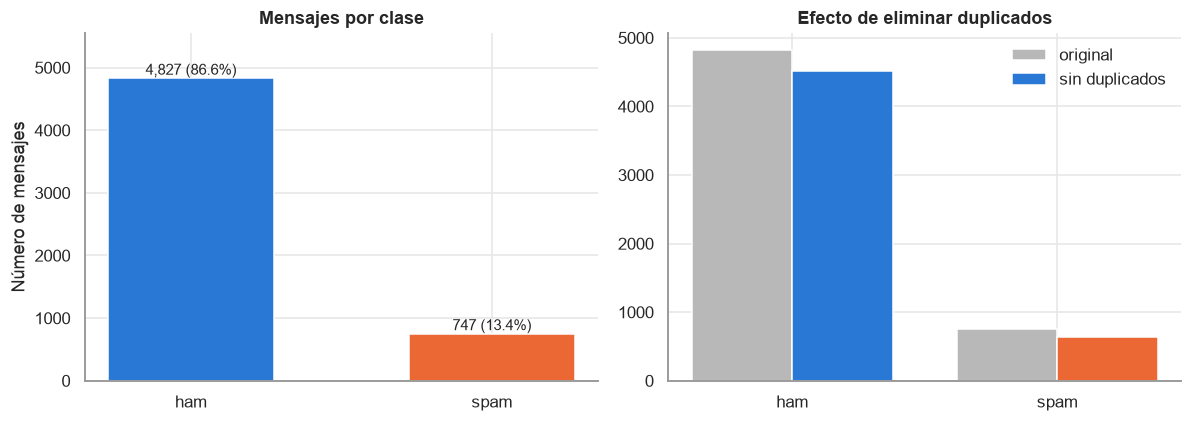

Ratio de desbalance ham:spam = 6.5:1


In [4]:
counts = df.label.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index], width=0.55)
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width()/2, v + 60, f"{v:,} ({v/len(df):.1%})", ha="center", fontsize=10)
axes[0].set_title("Mensajes por clase"); axes[0].set_ylabel("Número de mensajes"); axes[0].set_ylim(0, counts.max()*1.15)

dedup = df.drop_duplicates("text").label.value_counts()
x = np.arange(2); w = 0.38
axes[1].bar(x - w/2, counts[["ham","spam"]], w, label="original", color="#b8b8b8")
axes[1].bar(x + w/2, dedup[["ham","spam"]], w, label="sin duplicados", color=[HAM, SPAM])
axes[1].set_xticks(x, ["ham", "spam"]); axes[1].set_title("Efecto de eliminar duplicados"); axes[1].legend(frameon=False)
plt.tight_layout(); savefig("01_class_distribution"); plt.show()
print(f"Ratio de desbalance ham:spam = {counts['ham']/counts['spam']:.1f}:1")

El dataset está **fuertemente desbalanceado (≈6,5 : 1)**: un clasificador trivial que diga siempre *ham* obtendría 86,6 % de *accuracy*. Esto justifica usar F1/recall/ROC-AUC y partición **estratificada**.

### 2.2 Ingeniería de variables para el análisis

Extraemos características numéricas de cada mensaje: longitud (caracteres, palabras, oraciones), proporción de mayúsculas y dígitos, signos de puntuación y exclamación, y presencia de URL, número telefónico (≥5 dígitos) o símbolo de moneda.

In [5]:
feat = extract_features(df)
feat.groupby("label")[NUMERIC_FEATURES].mean().T.round(3).rename(columns={"ham": "media ham", "spam": "media spam"}) \
    .assign(**{"ratio spam/ham": lambda t: (t["media spam"] / t["media ham"].replace(0, np.nan)).round(2)})

label,media ham,media spam,ratio spam/ham
n_chars,71.438,138.635,1.94
n_words,14.304,23.912,1.67
n_sentences,2.728,3.984,1.46
avg_word_len,5.060,5.921,1.17
n_uppercase,4.098,15.470,3.78
uppercase_ratio,0.058,0.111,1.91
n_digits,0.305,15.813,51.85
digit_ratio,0.004,0.117,29.25
n_punctuation,3.959,5.718,1.44
n_exclamations,0.177,0.730,4.12


### 2.3 Longitud de los mensajes

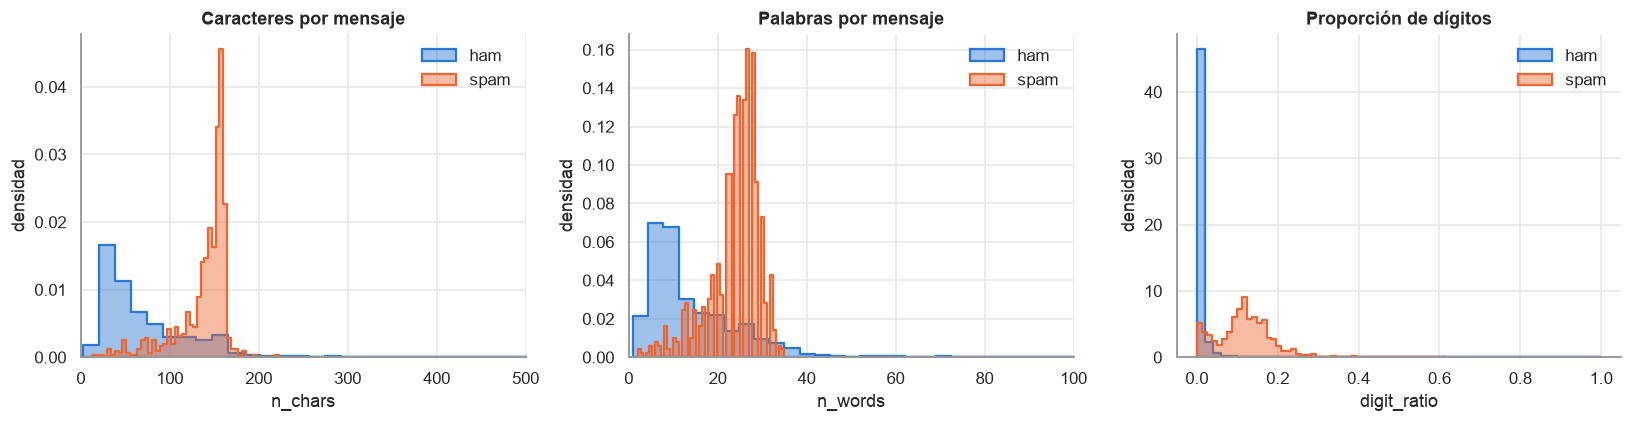

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["n_chars", "n_words", "digit_ratio"],
                          ["Caracteres por mensaje", "Palabras por mensaje", "Proporción de dígitos"]):
    for lbl in ["ham", "spam"]:
        sns.histplot(feat.loc[feat.label == lbl, col], ax=ax, color=PALETTE[lbl], label=lbl,
                     stat="density", bins=50, alpha=0.45, element="step", linewidth=1.5)
    ax.set_title(title); ax.set_ylabel("densidad"); ax.legend(frameon=False)
axes[0].set_xlim(0, 500); axes[1].set_xlim(0, 100)
plt.tight_layout(); savefig("02_length_distributions"); plt.show()

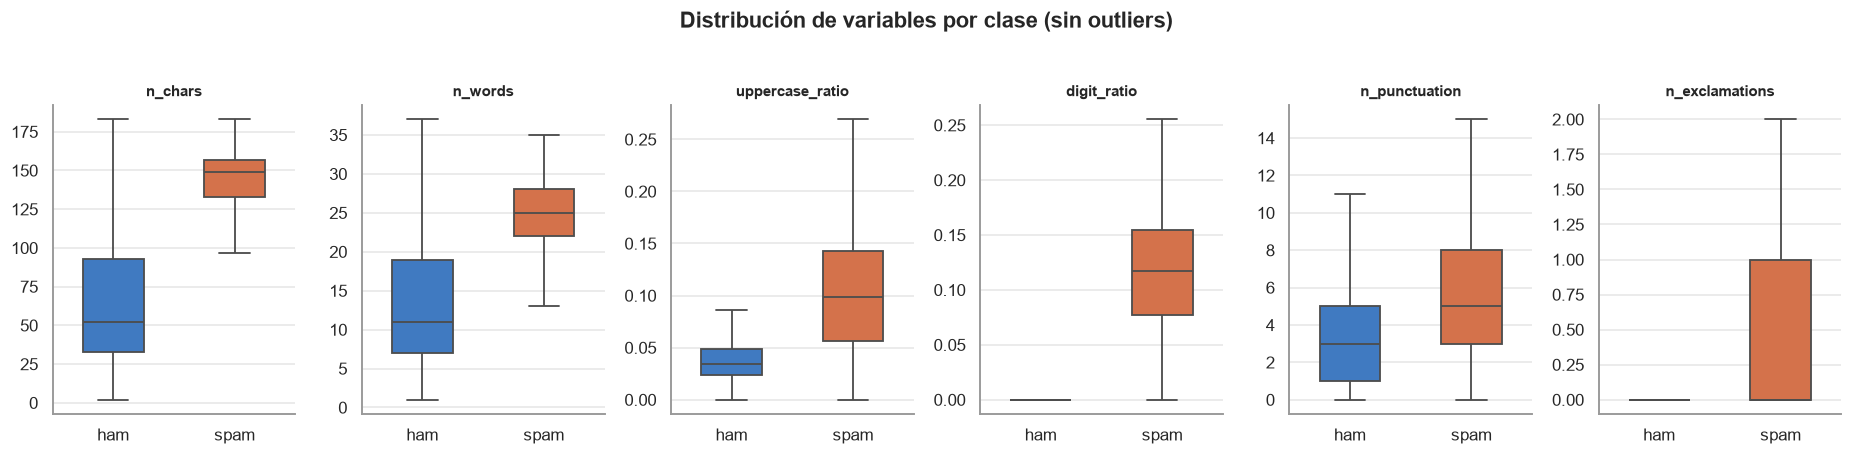

In [7]:
cols = ["n_chars", "n_words", "uppercase_ratio", "digit_ratio", "n_punctuation", "n_exclamations"]
fig, axes = plt.subplots(1, len(cols), figsize=(17, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(data=feat, x="label", y=c, ax=ax, palette=PALETTE, showfliers=False, width=0.5, linewidth=1.2)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Distribución de variables por clase (sin outliers)", fontweight="bold", y=1.03)
plt.tight_layout(); savefig("03_boxplots"); plt.show()

**Hallazgos:**
* Los mensajes **spam son más largos** (mediana ≈ 150 caracteres vs ≈ 50 en ham): el spam intenta aprovechar los 160 caracteres de un SMS.
* El spam contiene **muchos más dígitos** (números de teléfono, códigos cortos, precios) y más mayúsculas (*"URGENT!", "FREE"*).

Comprobamos estadísticamente que las diferencias no son azar con la prueba no paramétrica **Mann-Whitney U**:

In [8]:
rows = []
for c in NUMERIC_FEATURES:
    a, b = feat.loc[feat.label == "ham", c], feat.loc[feat.label == "spam", c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"variable": c, "mediana ham": a.median(), "mediana spam": b.median(),
                 "efecto (r rank-biserial)": 1 - 2*u/(len(a)*len(b)), "p-valor": p})
pd.DataFrame(rows).sort_values("efecto (r rank-biserial)", key=abs, ascending=False).round(4)

,variable,mediana ham,mediana spam,efecto (r rank-biserial),p-valor
6,n_digits,0.0000,16.0000,0.9308,0.0
7,digit_ratio,0.0000,0.1173,0.9190,0.0
4,n_uppercase,2.0000,14.0000,0.8032,0.0
11,has_phone,0.0000,1.0000,0.7557,0.0
0,n_chars,52.0000,149.0000,0.7446,0.0
1,n_words,11.0000,25.0000,0.6277,0.0
5,uppercase_ratio,0.0345,0.0987,0.6169,0.0
3,avg_word_len,4.9231,5.8148,0.6054,0.0
2,n_sentences,2.0000,4.0000,0.4297,0.0
8,n_punctuation,3.0000,5.0000,0.3870,0.0


### 2.4 Indicadores binarios: URL, teléfono y moneda

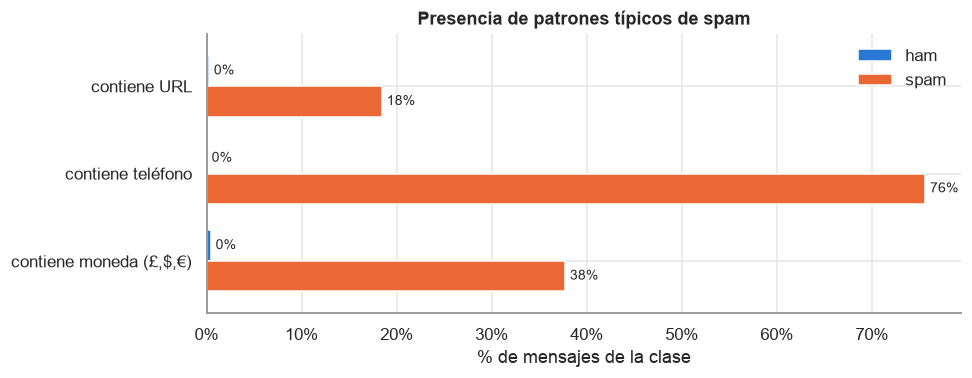

In [9]:
flags = feat.groupby("label")[["has_url", "has_phone", "has_currency"]].mean().T
flags.index = ["contiene URL", "contiene teléfono", "contiene moneda (£,$,€)"]
ax = flags.plot.barh(color=[HAM, SPAM], figsize=(9, 3.6), width=0.7)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel("% de mensajes de la clase")
ax.set_title("Presencia de patrones típicos de spam"); ax.legend(title="", frameon=False); ax.invert_yaxis()
for cont in ax.containers: ax.bar_label(cont, fmt=lambda v: f"{v:.0%}", padding=3, fontsize=9)
plt.tight_layout(); savefig("04_binary_flags"); plt.show()

Alrededor del **76 % del spam incluye un número telefónico** frente al 0,1 % del ham; el 38 % del spam menciona dinero (£, $, €) frente al 0,5 % del ham, y casi 1 de cada 5 spam trae una URL. Son señales muy discriminativas.

### 2.5 Matriz de correlación

Calculamos la correlación de Pearson entre todas las variables numéricas y la variable objetivo `target` (1 = spam). Con una variable binaria, la correlación de Pearson equivale a la **correlación punto-biserial**.

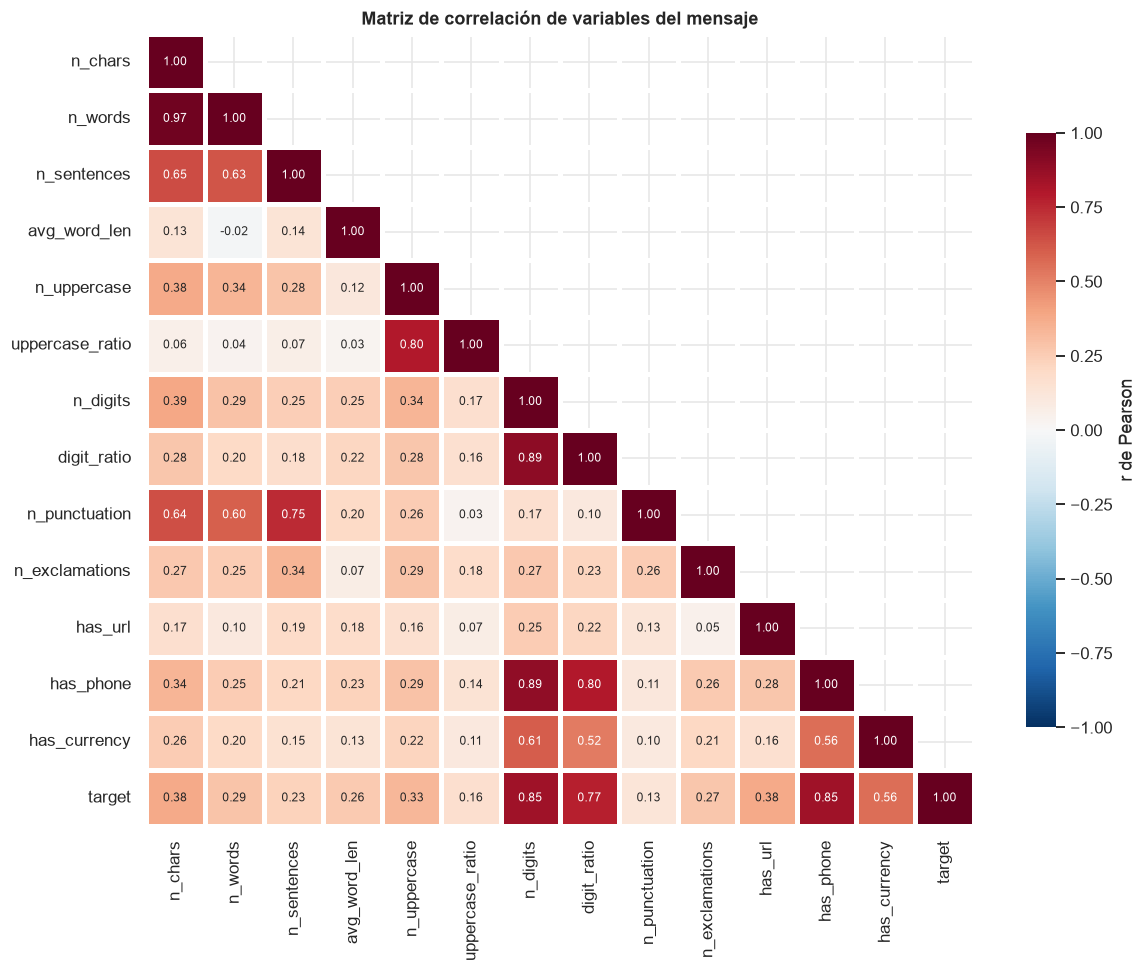

In [10]:
corr = feat[NUMERIC_FEATURES + ["target"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", annot_kws={"size": 8}, cbar_kws={"shrink": .75, "label": "r de Pearson"})
plt.title("Matriz de correlación de variables del mensaje")
plt.tight_layout(); savefig("05_correlation_matrix"); plt.show()

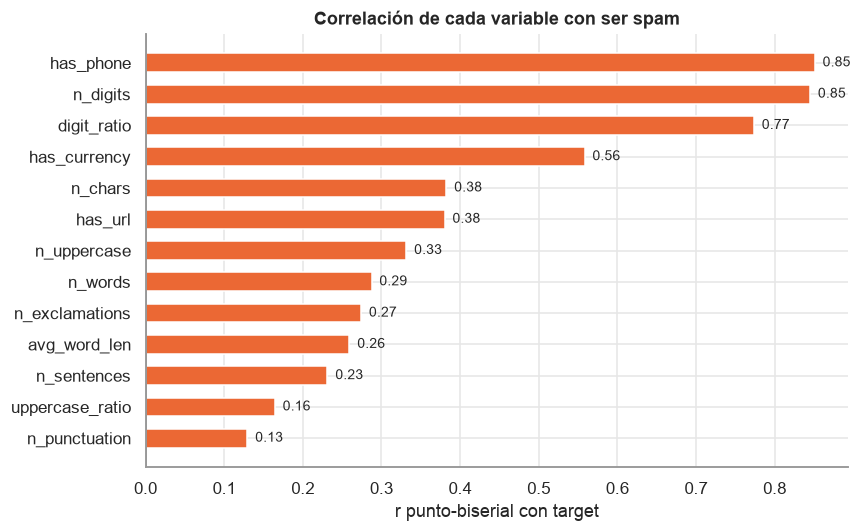

In [11]:
target_corr = corr["target"].drop("target").sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(target_corr.index, target_corr.values, color=[SPAM if v > 0 else HAM for v in target_corr.values], height=0.6)
ax.axvline(0, color="#666", lw=1)
for i, v in enumerate(target_corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_title("Correlación de cada variable con ser spam"); ax.set_xlabel("r punto-biserial con target")
plt.tight_layout(); savefig("06_target_correlation"); plt.show()

**Interpretación:**
* `has_phone` (r ≈ 0,85), `n_digits` (≈ 0,85), `digit_ratio` (≈ 0,77) y `has_currency` (≈ 0,56) son las variables **más correlacionadas con spam**.
* `n_chars` y `n_words` están **casi perfectamente correlacionadas entre sí** (r ≈ 0,97) y moderadamente con `n_punctuation` y `n_sentences` (0,6–0,75): todas miden la longitud, por lo que aportan información redundante (multicolinealidad).
* `n_punctuation` y `uppercase_ratio` son las de relación más débil con la clase (r < 0,17).

### 2.6 Vocabulario: palabras y bigramas más frecuentes

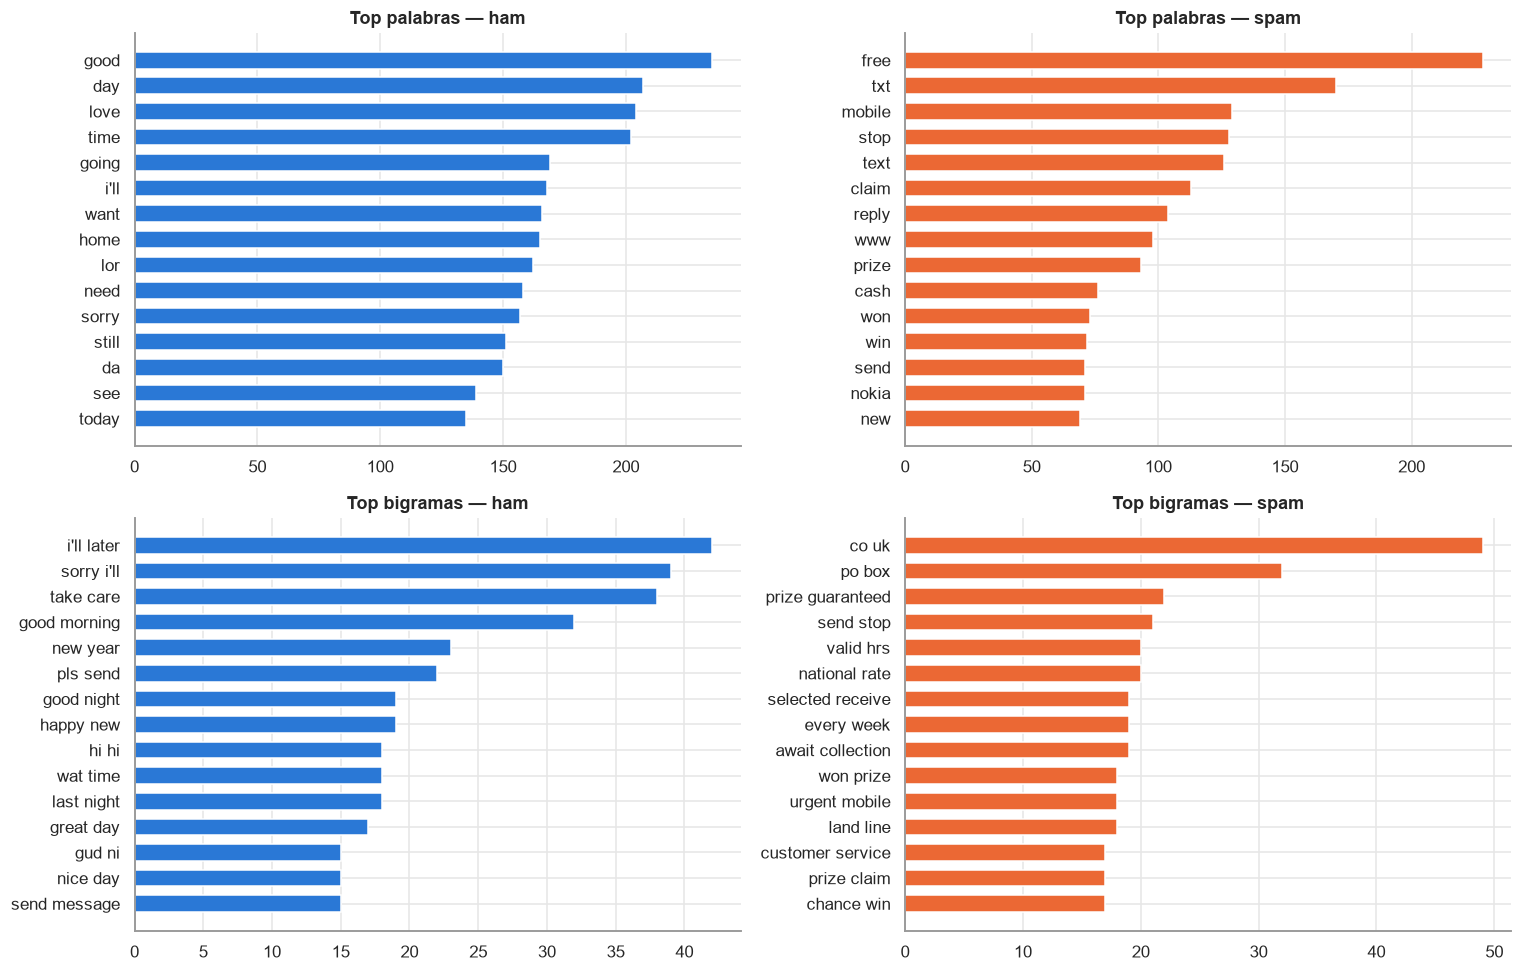

In [12]:
def top_ngrams(texts, n=1, k=15):
    c = Counter()
    for t in texts:
        toks = tokenize(t)
        c.update(zip(*[toks[i:] for i in range(n)]) if n > 1 else toks)
    return pd.DataFrame([(" ".join(w) if n > 1 else w, f) for w, f in c.most_common(k)], columns=["ngram", "freq"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for col, lbl in enumerate(["ham", "spam"]):
    texts = df.loc[df.label == lbl, "text"]
    for row, n in enumerate([1, 2]):
        t = top_ngrams(texts, n)
        axes[row, col].barh(t.ngram[::-1], t.freq[::-1], color=PALETTE[lbl], height=0.65)
        axes[row, col].set_title(f"Top {'palabras' if n == 1 else 'bigramas'} — {lbl}")
plt.tight_layout(); savefig("07_top_ngrams"); plt.show()

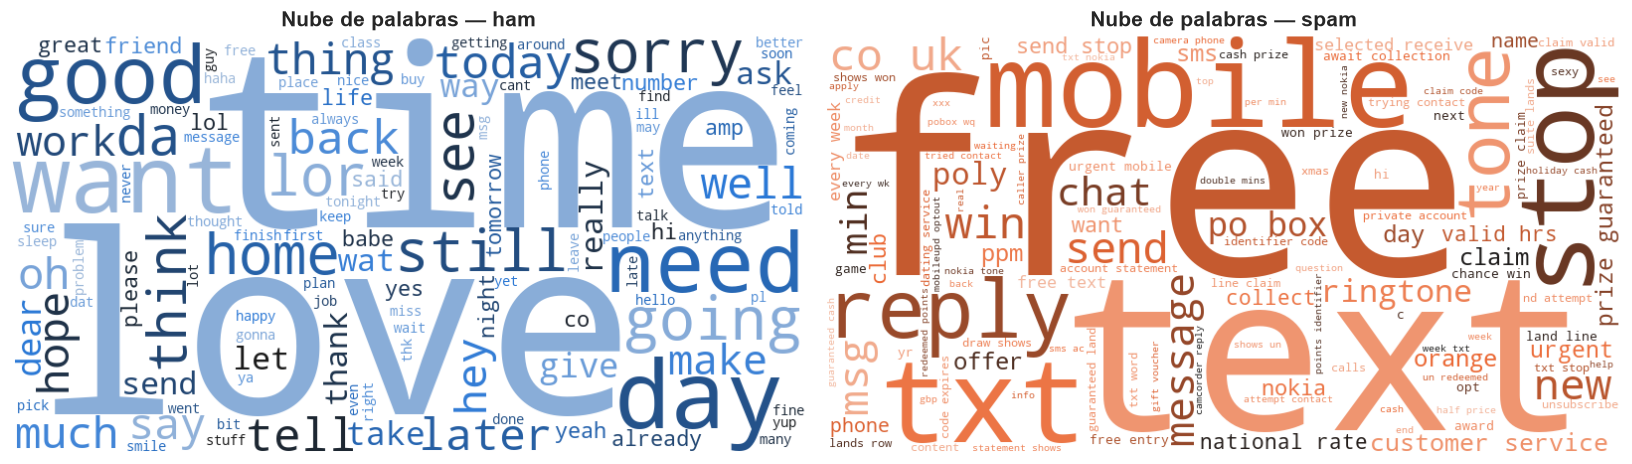

In [13]:
from wordcloud import WordCloud
from matplotlib.colors import LinearSegmentedColormap
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, lbl in zip(axes, ["ham", "spam"]):
    cmap = LinearSegmentedColormap.from_list(lbl, ["#9db8d9" if lbl == "ham" else "#f2b79e", PALETTE[lbl], "#1b1b1b"])
    words = " ".join(" ".join(tokenize(t)) for t in df.loc[df.label == lbl, "text"])
    wc = WordCloud(width=800, height=420, background_color="white", colormap=cmap, max_words=120,
                   random_state=RANDOM_STATE).generate(words)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"Nube de palabras — {lbl}", fontsize=14)
plt.tight_layout(); savefig("08_wordclouds"); plt.show()

El vocabulario del **spam** gira en torno a premios y acciones (*free, txt, claim, prize, won, mobile, reply, stop, cash, urgent*), con bigramas como *"please call"*, *"po box"*, *"guaranteed call"*. El **ham** es conversacional e informal, con abreviaturas propias del SMS (*lor, da, ur, gonna, wat*).

### 2.7 Términos más discriminativos (χ²)

In [14]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2
cv = CountVectorizer(tokenizer=tokenize, lowercase=False, min_df=5, token_pattern=None)
X = cv.fit_transform(df.text)
chi, p = chi2(X, df.target)
vocab = np.array(cv.get_feature_names_out())
spam_rate = np.asarray((X[df.target.values == 1] > 0).mean(0)).ravel()
ham_rate = np.asarray((X[df.target.values == 0] > 0).mean(0)).ravel()
top = pd.DataFrame({"término": vocab, "chi2": chi, "% en spam": spam_rate*100, "% en ham": ham_rate*100}) \
        .sort_values("chi2", ascending=False).head(15).round(2)
top

,término,chi2,% en spam,% en ham
507,free,1073.30,23.29,1.22
1487,txt,989.23,20.75,0.27
247,claim,730.19,14.46,0.00
887,mobile,720.11,15.39,0.31
1653,www,616.68,13.12,0.04
1094,prize,600.95,11.24,0.00
1335,stop,585.52,13.92,0.75
1627,won,471.71,9.77,0.00
1398,text,440.70,14.59,1.39
959,nokia,434.45,7.23,0.06


### 2.8 Proyección 2D de los mensajes (TF-IDF + SVD)

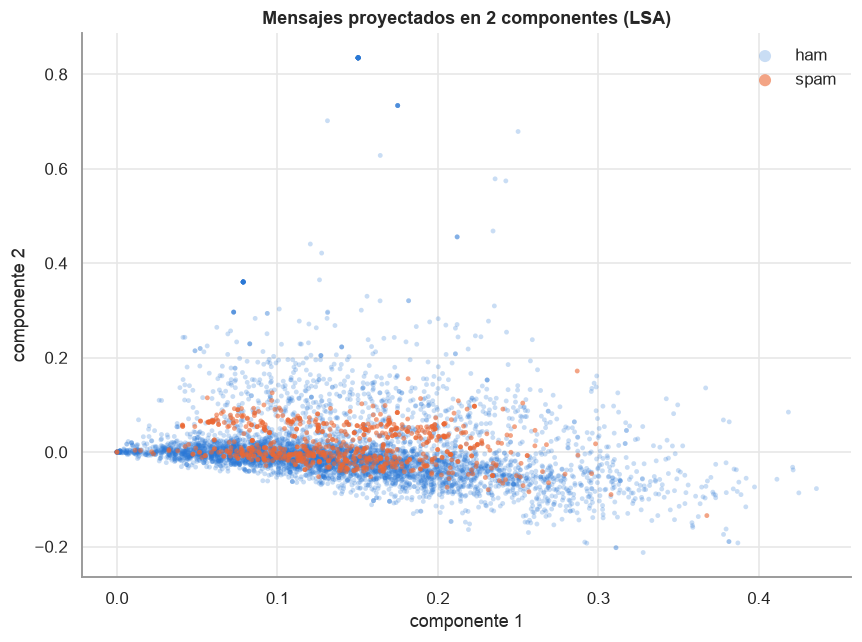

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
tfidf = TfidfVectorizer(min_df=3, sublinear_tf=True).fit_transform(df.text)
emb = TruncatedSVD(2, random_state=RANDOM_STATE).fit_transform(tfidf)
fig, ax = plt.subplots(figsize=(8, 6))
for lbl, alpha in [("ham", 0.25), ("spam", 0.6)]:
    m = df.label == lbl
    ax.scatter(emb[m, 0], emb[m, 1], s=10, alpha=alpha, color=PALETTE[lbl], label=lbl, edgecolors="none")
ax.set_title("Mensajes proyectados en 2 componentes (LSA)"); ax.set_xlabel("componente 1"); ax.set_ylabel("componente 2")
ax.legend(frameon=False, markerscale=2.5)
plt.tight_layout(); savefig("09_tfidf_svd_projection"); plt.show()

Incluso con solo dos dimensiones lineales, el spam se concentra en una región propia del espacio, lo que anticipa que el problema es **separable** con un buen modelo de texto.

## 3. Preparación de los datos

1. **Eliminar duplicados** (5.574 → 5.160 mensajes) para evitar fuga entre particiones.
2. **Partición estratificada 70 / 15 / 15** (*train / validation / test*) con semilla fija → misma proporción de spam en cada parte.
3. **Tokenización** con el tokenizador del modelo (`MiniLM`, máx. 128 tokens). No hace falta limpiar el texto (minúsculas, stopwords…), porque el transformer aprovecha la información de mayúsculas, puntuación y números.

La lógica vive en `src/spam_detection/data_split.py` (reutilizada por los scripts y por la app).

In [16]:
from spam_detection.data_split import make_splits
splits = make_splits()
pd.DataFrame({k: {"n": len(v), "spam": int(v.target.sum()), "% spam": round(v.target.mean()*100, 2)}
              for k, v in splits.items()}).T

,n,spam,% spam
train,3612.0,450.0,12.46
val,774.0,96.0,12.40
test,774.0,96.0,12.40


In [17]:
train, val, test = splits["train"], splits["val"], splits["test"]
assert not set(train.text) & set(test.text), "fuga de datos"
print("✔ Sin solapamiento de textos entre train y test")

✔ Sin solapamiento de textos entre train y test


## 4. Modelado

### 4.1 Modelo de Hugging Face *tal cual* (zero-shot)

[`Goodmotion/spam-mail-classifier`](https://huggingface.co/Goodmotion/spam-mail-classifier) es un **`microsoft/Multilingual-MiniLM-L12-H384`** (≈118 M parámetros) afinado para clasificar **asuntos de correo electrónico** en `NOSPAM` (índice 0) y `SPAM` (índice 1). Lo envolvemos en la clase `SpamClassifier` (`src/spam_detection/model.py`), que tokeniza por lotes, aplica *softmax* y devuelve `P(spam)`.

In [18]:
import time
from spam_detection.model import SpamClassifier
from spam_detection.evaluation import compute_metrics

zero_shot = SpamClassifier(model_name=MODEL_NAME)
t0 = time.perf_counter()
test = test.assign(prob_zero_shot=zero_shot.predict_proba(test.text.tolist()))
print(f"Inferencia sobre {len(test)} mensajes: {time.perf_counter()-t0:.1f}s")
m_zero = compute_metrics(test.target, test.prob_zero_shot)
{k: round(v, 4) for k, v in m_zero.items() if isinstance(v, float)}

W1103 22:14:01.075000 47696 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Inferencia sobre 774 mensajes: 3.6s


{'threshold': 0.5,
 'accuracy': 0.4225,
 'precision': 0.1483,
 'recall': 0.7708,
 'f1': 0.2487,
 'roc_auc': 0.6557,
 'average_precision': 0.2067}

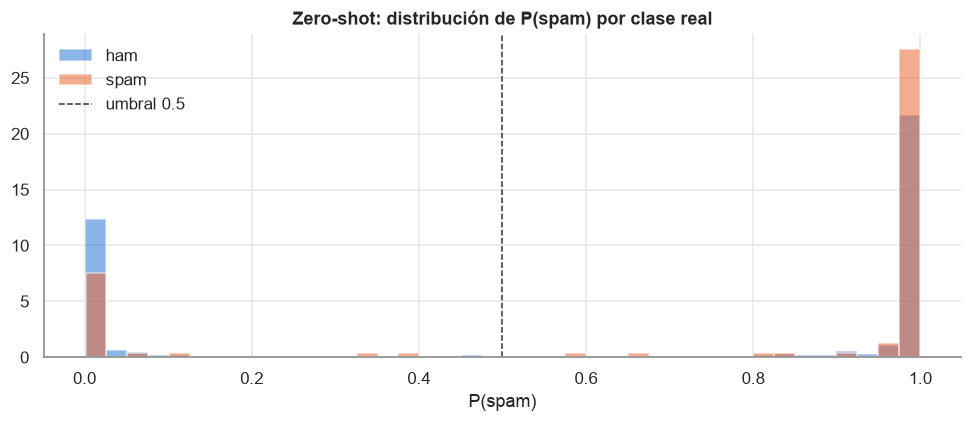

,text,prob_zero_shot
371,Sos! Any amount i can get pls.,0.999161
625,You intrepid duo you! Have a great time and see you both soon.,0.999161
122,Are you free now?can i call now?,0.999161
587,"Save yourself the stress. If the person has a dorm account, just send your account details and the money will be sen...",0.999159
595,Your right! I'll make the appointment right now.,0.999157
320,What you need. You have a person to give na.,0.999153


In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
for lbl in ["ham", "spam"]:
    ax.hist(test.loc[test.label == lbl, "prob_zero_shot"], bins=40, alpha=0.55, color=PALETTE[lbl], label=lbl, density=True)
ax.axvline(0.5, color="#333", ls="--", lw=1, label="umbral 0.5")
ax.set_title("Zero-shot: distribución de P(spam) por clase real"); ax.set_xlabel("P(spam)"); ax.legend(frameon=False)
plt.tight_layout(); savefig("10_zero_shot_probabilities"); plt.show()
test.loc[test.label == "ham"].nlargest(6, "prob_zero_shot")[["text", "prob_zero_shot"]]

**Diagnóstico — *domain shift*:** el modelo original obtiene un F1 de spam muy bajo y clasifica como spam con ~99,9 % de confianza mensajes legítimos como *"Are you free now? can i call now?"*. La causa es la **diferencia de dominio**: fue entrenado con **asuntos de e-mail** (y en buena parte en francés), mientras que nuestro dataset son **SMS informales en inglés**, con abreviaturas (*u, ur, lor, da*) y llenos de palabras como *free* o *call* que en el contexto de un correo serían sospechosas.

La solución estándar es **transfer learning**: conservar los pesos pre-entrenados del mismo modelo y **afinarlo (fine-tuning)** con el conjunto de entrenamiento del SMS Spam Collection.

### 4.2 Baseline clásico: TF-IDF + Regresión Logística

Como referencia, entrenamos un modelo clásico con n-gramas de palabras (1–2) y de caracteres (3–5), con `class_weight="balanced"`.

In [20]:
from spam_detection.baseline import build_baseline
baseline = build_baseline().fit(train.text, train.target)
test = test.assign(prob_baseline=baseline.predict_proba(test.text)[:, 1])
m_base = compute_metrics(test.target, test.prob_baseline)
{k: round(v, 4) for k, v in m_base.items() if isinstance(v, float)}

{'threshold': 0.5,
 'accuracy': 0.9832,
 'precision': 0.956,
 'recall': 0.9062,
 'f1': 0.9305,
 'roc_auc': 0.9945,
 'average_precision': 0.9791}

### 4.3 Fine-tuning de `Goodmotion/spam-mail-classifier` sobre los SMS

Configuración (`src/spam_detection/train.py`):

| Hiperparámetro | Valor |
|---|---|
| Modelo base | `Goodmotion/spam-mail-classifier` (MiniLM-L12-H384) |
| Épocas | 3 (se guarda la mejor según F1 en validación) |
| Batch size | 16 |
| Optimizador | AdamW, lr = 3e-5, weight decay = 0.01 |
| Scheduler | lineal con 10 % de *warm-up* |
| Pérdida | Cross-entropy **ponderada por clase** (compensa el desbalance) |
| Longitud máx. | 128 tokens |
| Hardware | Apple Silicon (MPS) — ≈ 1 min en total |

El entrenamiento se ejecuta con `python scripts/train_model.py`. Si el *checkpoint* no existe se entrena aquí; si existe, se reutiliza.

,epoch,train_loss,val_f1,seconds
0,1,0.368685,0.952880,20.2
1,2,0.104413,0.962567,14.0
2,3,0.061646,0.963351,13.7


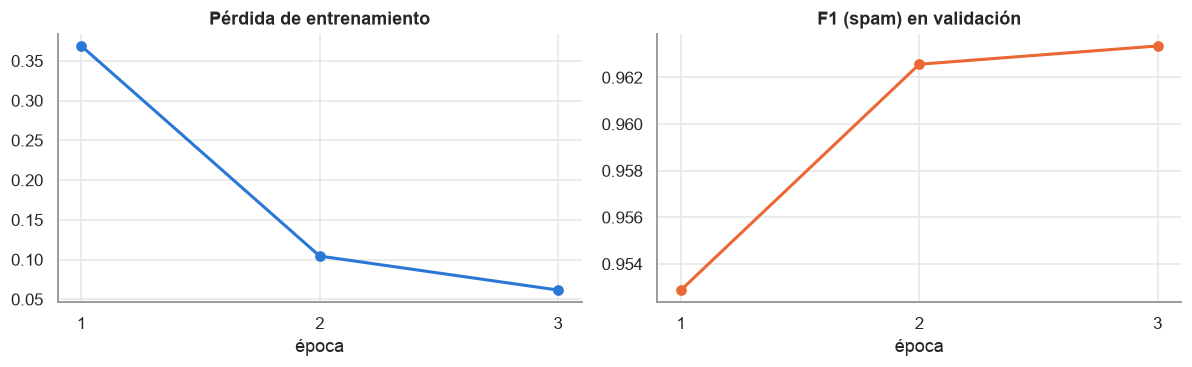

In [21]:
RETRAIN = False
if RETRAIN or not (FINETUNED_MODEL_DIR / "config.json").exists():
    from spam_detection.train import fine_tune
    summary = fine_tune()
else:
    summary = json.loads((FINETUNED_MODEL_DIR / "training_summary.json").read_text())
hist = pd.DataFrame(summary["history"])
display(hist)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.epoch, hist.train_loss, marker="o", color=HAM, lw=2); ax[0].set_title("Pérdida de entrenamiento"); ax[0].set_xlabel("época")
ax[1].plot(hist.epoch, hist.val_f1, marker="o", color=SPAM, lw=2); ax[1].set_title("F1 (spam) en validación"); ax[1].set_xlabel("época")
for a in ax: a.set_xticks(hist.epoch)
plt.tight_layout(); savefig("11_training_curves"); plt.show()

In [22]:
fine_tuned = SpamClassifier(model_name=str(FINETUNED_MODEL_DIR))
test = test.assign(prob_fine_tuned=fine_tuned.predict_proba(test.text.tolist()))
m_ft = compute_metrics(test.target, test.prob_fine_tuned)
{k: round(v, 4) for k, v in m_ft.items() if isinstance(v, float)}

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'threshold': 0.5,
 'accuracy': 0.9884,
 'precision': 0.9485,
 'recall': 0.9583,
 'f1': 0.9534,
 'roc_auc': 0.9994,
 'average_precision': 0.9958}

## 5. Evaluación (conjunto de test, nunca visto)

### 5.1 Comparación de modelos

In [23]:
MODELS = {"zero_shot": ("HF zero-shot", "#9a9a9a"), "baseline": ("TF-IDF + LogReg", THIRD), "fine_tuned": ("HF fine-tuned", HAM)}
results = {"zero_shot": m_zero, "baseline": m_base, "fine_tuned": m_ft}
table = pd.DataFrame({MODELS[k][0]: {m: v[m] for m in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]}
                      for k, v in results.items()}).T
table.style.format("{:.4f}").highlight_max(axis=0, props="font-weight:bold; background-color:#dbeafe")

,accuracy,precision,recall,f1,roc_auc,average_precision
HF zero-shot,0.4225,0.1483,0.7708,0.2487,0.6557,0.2067
TF-IDF + LogReg,0.9832,0.9560,0.9062,0.9305,0.9945,0.9791
HF fine-tuned,0.9884,0.9485,0.9583,0.9534,0.9994,0.9958


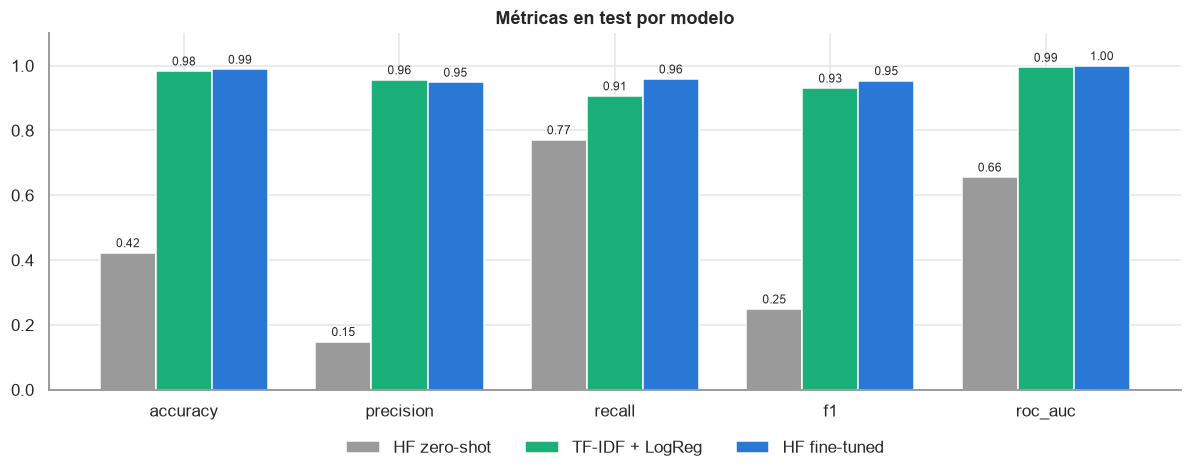

In [24]:
metrics_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]
x = np.arange(len(metrics_plot)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (k, (name, color)) in enumerate(MODELS.items()):
    vals = [results[k][m] for m in metrics_plot]
    b = ax.bar(x + (i-1)*w, vals, w, label=name, color=color)
    ax.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x, metrics_plot); ax.set_ylim(0, 1.1); ax.set_title("Métricas en test por modelo")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); savefig("12_model_comparison"); plt.show()

### 5.2 Matrices de confusión

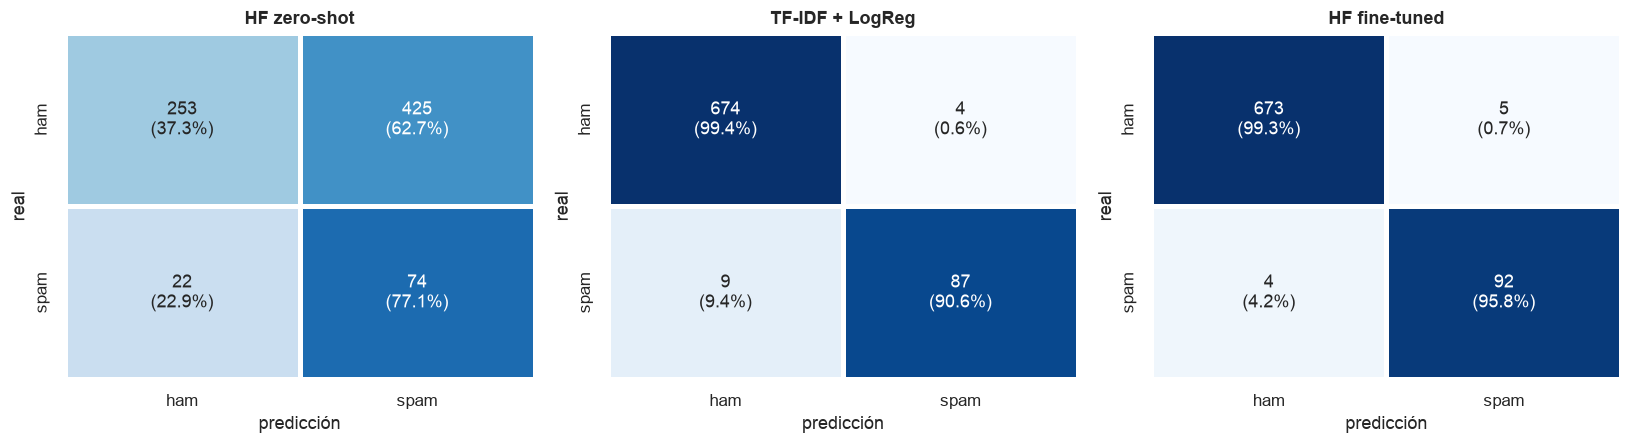

In [25]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (k, (name, _)) in zip(axes, MODELS.items()):
    cm = confusion_matrix(test.target, (test[f"prob_{k}"] >= 0.5).astype(int))
    pct = cm / cm.sum(1, keepdims=True)
    labels = np.array([[f"{c}\n({p:.1%})" for c, p in zip(r1, r2)] for r1, r2 in zip(cm, pct)])
    sns.heatmap(pct, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"], linewidths=2, linecolor="white")
    ax.set_title(name); ax.set_xlabel("predicción"); ax.set_ylabel("real")
plt.tight_layout(); savefig("13_confusion_matrices"); plt.show()

### 5.3 Curvas ROC y Precision-Recall

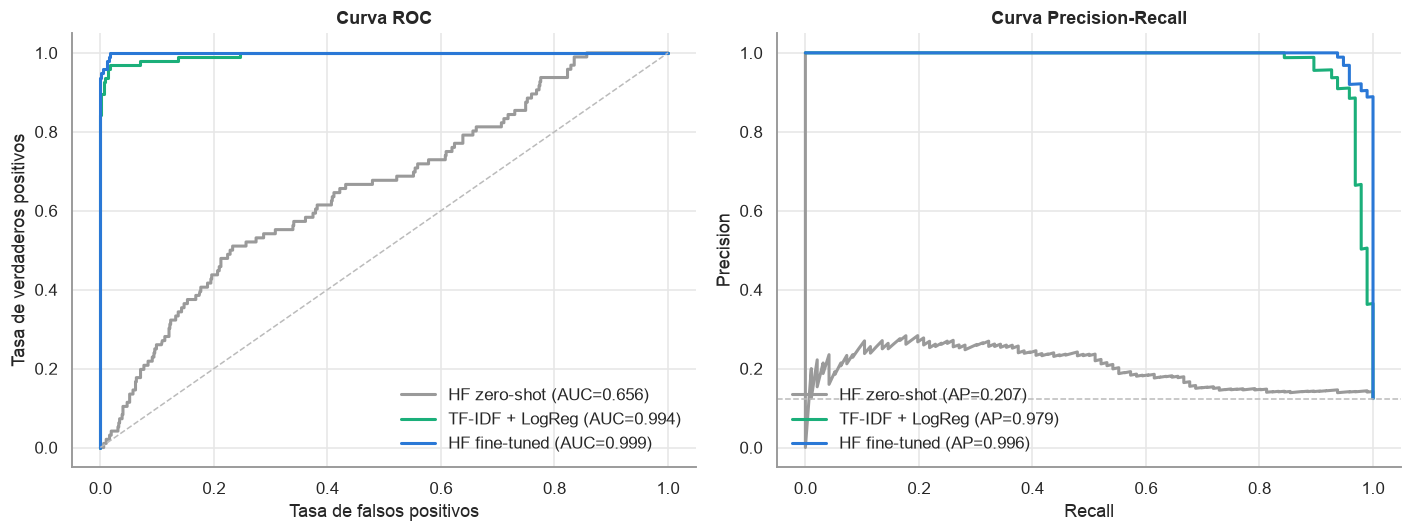

In [26]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for k, (name, color) in MODELS.items():
    fpr, tpr, _ = roc_curve(test.target, test[f"prob_{k}"])
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC={results[k]['roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(test.target, test[f"prob_{k}"])
    axes[1].plot(rc, pr, color=color, lw=2, label=f"{name} (AP={results[k]['average_precision']:.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="#bbb", lw=1)
axes[0].set(title="Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axes[1].axhline(test.target.mean(), ls="--", color="#bbb", lw=1)
axes[1].set(title="Curva Precision-Recall", xlabel="Recall", ylabel="Precision")
for a in axes: a.legend(frameon=False, loc="lower right" if a is axes[0] else "lower left")
plt.tight_layout(); savefig("14_roc_pr_curves"); plt.show()

### 5.4 Elección del umbral de decisión

El umbral se ajusta en **validación** (no en test) para no sesgar la evaluación.

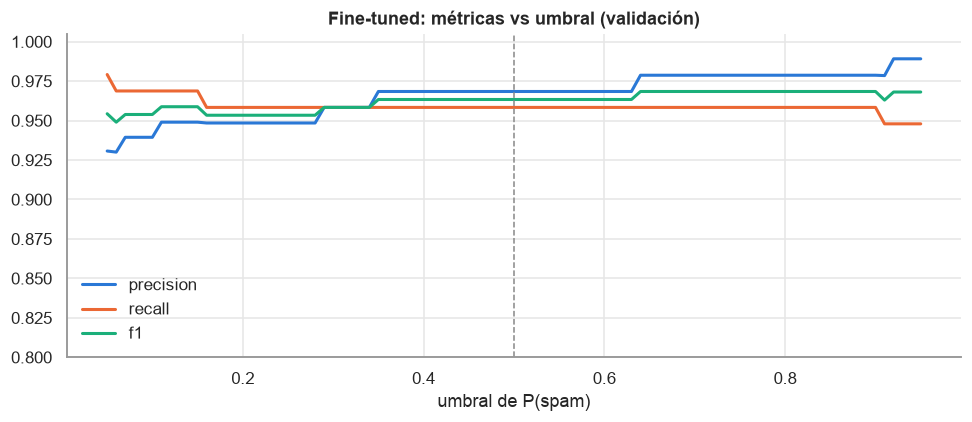

Mejor F1 en validación = 0.9684 con umbral 0.64


In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score
val_prob = fine_tuned.predict_proba(val.text.tolist())
th = np.linspace(0.05, 0.95, 91)
curve = pd.DataFrame({"umbral": th,
    "precision": [precision_score(val.target, np.array(val_prob) >= t, zero_division=0) for t in th],
    "recall":    [recall_score(val.target, np.array(val_prob) >= t) for t in th],
    "f1":        [f1_score(val.target, np.array(val_prob) >= t) for t in th]})
best = curve.loc[curve.f1.idxmax()]
fig, ax = plt.subplots(figsize=(9, 4))
for c, color in [("precision", HAM), ("recall", SPAM), ("f1", THIRD)]:
    ax.plot(curve.umbral, curve[c], label=c, color=color, lw=2)
ax.axvline(0.5, color="#888", ls="--", lw=1); ax.set_ylim(0.8, 1.005)
ax.set(title="Fine-tuned: métricas vs umbral (validación)", xlabel="umbral de P(spam)"); ax.legend(frameon=False)
plt.tight_layout(); savefig("15_threshold_analysis"); plt.show()
print(f"Mejor F1 en validación = {best.f1:.4f} con umbral {best.umbral:.2f}")

Las curvas son casi planas: el F1 en validación solo varía entre ≈0,95 y ≈0,97 para umbrales de 0,1 a 0,9, porque el modelo afinado está **bien separado** (probabilidades cercanas a 0 o a 1). La mejora del umbral óptimo frente a 0,5 equivale a un único mensaje de validación, así que se mantiene el umbral por defecto **0,5** en la aplicación (configurable con la variable de entorno `SPAM_THRESHOLD`).

### 5.5 Análisis de errores del modelo final

In [28]:
test["pred_ft"] = (test.prob_fine_tuned >= 0.5).astype(int)
errors = test[test.pred_ft != test.target].assign(
    tipo=lambda d: np.where(d.target == 1, "Falso negativo (spam no detectado)", "Falso positivo (ham marcado spam)"))
print(errors.tipo.value_counts().to_string())
errors.sort_values("tipo")[["tipo", "text", "prob_fine_tuned"]].round(3)

tipo
Falso positivo (ham marcado spam)     5
Falso negativo (spam no detectado)    4


,tipo,text,prob_fine_tuned
269,Falso negativo (spam no detectado),Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your op...,0.023
311,Falso negativo (spam no detectado),thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you see the ...,0.253
349,Falso negativo (spam no detectado),"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all...",0.052
763,Falso negativo (spam no detectado),3. You have received your mobile content. Enjoy,0.202
324,Falso positivo (ham marcado spam),Unlimited texts. Limited minutes.,0.919
342,Falso positivo (ham marcado spam),"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru ema...",0.997
631,Falso positivo (ham marcado spam),Your bill at 3 is £33.65 so thats not bad!,0.996
650,Falso positivo (ham marcado spam),Can you plz tell me the ans. BSLVYL sent via fullonsms.com,0.997
691,Falso positivo (ham marcado spam),I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,0.789


Los errores restantes son casos genuinamente ambiguos: spam muy corto o sin números de teléfono/premios, o mensajes legítimos que hablan de dinero, promociones u ofertas reales.

### 5.6 Guardar métricas

In [29]:
report = {"split": "test", "n_test": len(test),
          "models": {k: {**v, "model": MODELS[k][0]} for k, v in results.items()}}
(ROOT / "reports" / "metrics.json").write_text(json.dumps(report, indent=2))
print("Figuras guardadas en:", FIGURES_DIR.relative_to(ROOT))
sorted(p.name for p in FIGURES_DIR.glob("*.png"))

Figuras guardadas en: reports/figures


['01_class_distribution.png',
 '02_length_distributions.png',
 '03_boxplots.png',
 '04_binary_flags.png',
 '05_correlation_matrix.png',
 '06_target_correlation.png',
 '07_top_ngrams.png',
 '08_wordclouds.png',
 '09_tfidf_svd_projection.png',
 '10_zero_shot_probabilities.png',
 '11_training_curves.png',
 '12_model_comparison.png',
 '13_confusion_matrices.png',
 '14_roc_pr_curves.png',
 '15_threshold_analysis.png']

## 6. Despliegue — SpamShield Mail (Flask)

1. `scripts/build_email_db.py` convierte los **mensajes del conjunto de test** (no vistos en entrenamiento) en correos *dummy* con remitente, dirección y asunto, y los guarda en `data/processed/emails.json`.
2. La app (`app/`) carga el modelo afinado una sola vez y expone una API REST:
   * `POST /api/generate` — toma correos aleatorios del JSON, los **clasifica** y los entrega en **Bandeja de entrada** o **Spam**.
   * `POST /api/compose` — permite redactar un correo propio y ver a qué carpeta llega.
   * `GET /api/stats` — contadores por carpeta y métricas en vivo frente a la etiqueta real.
3. La interfaz imita un cliente de correo: dos carpetas con contadores, lista de mensajes, vista de detalle con la probabilidad de spam, botones *“No es spam” / “Marcar como spam”* y recepción automática de correos.

```bash
python scripts/build_email_db.py
python -m app            # http://127.0.0.1:8000
```

Ejemplo de uso del mismo clasificador que utiliza la app:

In [30]:
demo = ["Congratulations! You've won a £1000 Tesco gift card. Text CLAIM to 80086 now!",
        "Hey, are we still on for dinner tonight at 8?",
        "URGENT: your account is suspended, verify at www.secure-login-check.com",
        "Can you send me the slides from today's class?"]
pd.DataFrame([{"mensaje": t, **p.to_dict()} for t, p in zip(demo, fine_tuned.predict(demo))])

,mensaje,label,spam_probability,confidence
0,Congratulations! You've won a £1000 Tesco gift card. Text CLAIM to 80086 now!,spam,0.998703,0.998703
1,"Hey, are we still on for dinner tonight at 8?",ham,0.001442,0.998558
2,"URGENT: your account is suspended, verify at www.secure-login-check.com",spam,0.998651,0.998651
3,Can you send me the slides from today's class?,ham,0.005394,0.994606


## 7. Conclusiones

1. **EDA:** el dataset está desbalanceado (13,4 % spam) y contiene ~400 duplicados. El spam es más largo, tiene muchos más dígitos, números telefónicos, símbolos de moneda y un vocabulario muy característico (*free, claim, prize, txt, call*).
2. **El modelo de Hugging Face sin adaptar no sirve para SMS** (F1 ≈ 0,25) por *domain shift*: fue entrenado con asuntos de e-mail.
3. **El fine-tuning del mismo modelo** con ~3.600 SMS y 3 épocas (≈1 min) lo lleva a **F1 ≈ 0,95 y ROC-AUC ≈ 0,999**, superando al baseline TF-IDF + Regresión Logística, sobre todo en *recall*.
4. El modelo se despliega en una app web Flask que simula un buzón real con bandeja de entrada, spam, contadores y métricas en vivo.

**Trabajo futuro:** evaluar con correos electrónicos reales (p. ej. Enron-Spam), usar validación cruzada para estimar la varianza de las métricas, explicar predicciones con SHAP/atención y añadir aprendizaje continuo a partir de las correcciones del usuario (“No es spam”).